# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Umar Faruq Manek
- **Email:** umarfm18@gmail.com
- **ID Dicoding:** umarfaruqmanek

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

### Rumusan Pertanyaan Bisnis Proyek Ini:

1. **Pertanyaan 1 (Pengaruh Cuaca & Musim):**
   - **Rumusan:** *Bagaimana pengaruh kondisi cuaca (`weathersit`: cerah, berkabut, hujan/salju) dan pergantian musim (`season`: spring, summer, fall, winter) terhadap rata-rata jumlah penyewaan sepeda harian (`cnt`) sepanjang tahun 2011–2012, dan pada kondisi ekstrem seperti apa terjadi penurunan penyewaan yang signifikan sehingga memerlukan penyesuaian operasional armada?*
   - **Kesesuaian Prinsip SMART:**
     - **Specific:** Fokus menguji dampak cuaca dan musim secara spesifik terhadap volume penyewaan harian sepeda.
     - **Measurable:** Terukur melalui rata-rata dan total penyewaan harian (`cnt`).
     - **Action-Oriented:** Mengarahkan keputusan jadwal perawatan armada (*maintenance*) dan penyesuaian jumlah sepeda aktif di jalan saat cuaca buruk.
     - **Relevant:** Faktor cuaca dan iklim merupakan penentu utama keselamatan dan kenyamanan pengguna dalam layanan bike sharing.
     - **Time-bound:** Terikat waktu pada periode data 2011 hingga 2012 (rentang 731 hari observasi).

2. **Pertanyaan 2 (Pola Jam Sibuk & Karakteristik Pengguna):**
   - **Rumusan:** *Bagaimana pola peminjaman sepeda per jam (`hr`) berbeda antara hari kerja (`workingday`) dan hari libur/akhir pekan (`weekend/holiday`), serta bagaimana perbedaan perilaku antara pengguna kasual (`casual`) vs pengguna terdaftar (`registered`) sepanjang tahun 2011–2012 untuk mengoptimalkan ketersediaan unit sepeda di jam-jam sibuk (*peak hours*)?*
   - **Kesesuaian Prinsip SMART:**
     - **Specific:** Membedah kurva distribusi jam peminjaman (0–23) lintas kategori hari dan segmentasi tipe pengguna.
     - **Measurable:** Dihitung dari rata-rata volume peminjaman per jam serta rasio pengguna kasual vs terdaftar.
     - **Action-Oriented:** Menentukan jadwal penyeimbangan unit di stasiun (*dock rebalancing*) dan merancang kampanye konversi pengguna kasual menjadi anggota tahunan.
     - **Relevant:** Mencegah masalah stasiun kosong (*dock shortage*) saat jam sibuk komuter yang berdampak langsung pada kepuasan pelanggan.
     - **Time-bound:** Berdasarkan data jam operasional sepanjang tahun 2011 hingga 2012 (17.379 rekaman jam).

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi seaborn & matplotlib agar rapi dan informatif
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11

print("Semua library berhasil diimpor dengan sukses!")

Semua library berhasil diimpor dengan sukses!

## Data Wrangling

### Gathering Data

#### Memuat Data `day_df` dan `hour_df`

In [2]:
# Menentukan path dataset (mendukung data/ maupun Bike-sharing-dataset/)
day_path = 'data/day.csv' if os.path.exists('data/day.csv') else 'Bike-sharing-dataset/day.csv'
hour_path = 'data/hour.csv' if os.path.exists('data/hour.csv') else 'Bike-sharing-dataset/hour.csv'

day_df = pd.read_csv(day_path)
hour_df = pd.read_csv(hour_path)

print("Dimensi day_df :", day_df.shape)
print("Dimensi hour_df:", hour_df.shape)
print("\n5 Baris Pertama day_df:")
display_day = day_df.head()
print(display_day.iloc[:, :8])
print(display_day.iloc[:, 8:])

print("\n5 Baris Pertama hour_df:")
display_hour = hour_df.head()
print(display_hour.iloc[:, :9])
print(display_hour.iloc[:, 9:])

Dimensi day_df : (731, 16)
Dimensi hour_df: (17379, 17)

5 Baris Pertama day_df:
   instant      dteday  season  yr  mnth  holiday  weekday  workingday
0        1  2011-01-01       1   0     1        0        6           0
1        2  2011-01-02       1   0     1        0        0           0
2        3  2011-01-03       1   0     1        0        1           1
3        4  2011-01-04       1   0     1        0        2           1
4        5  2011-01-05       1   0     1        0        3           1
   weathersit      temp     atemp  ...  casual  registered   cnt
0           2  0.344167  0.363625  ...     331         654   985
1           2  0.363478  0.353739  ...     131         670   801
2           1  0.196364  0.189405  ...     120        1229  1349
3           1  0.200000  0.212122  ...     108        1454  1562
4           1  0.226957  0.229270  ...      82        1518  1600

[5 rows x 8 columns]

5 Baris Pertama hour_df:
   instant      dteday  season  yr  mnth  hr  holiday  

**Insight:**
- Dataset `day_df` berhasil dimuat dengan **731 baris** dan **16 kolom**, mewakili data agregasi harian selama kurun waktu dua tahun (2011–2012).
- Dataset `hour_df` berhasil dimuat dengan **17.379 baris** dan **17 kolom**, mencatat peminjaman per jam beserta kondisi cuaca terkait.
- Seluruh struktur kolom telah sesuai dengan dokumentasi resmi Bike Sharing Dataset.

### Assessing Data

#### Menilai Kualitas Data `day_df` dan `hour_df`

In [3]:
print("=== INFO DATA DAY_DF ===")
print(day_df.info())

print("\n=== INFO DATA HOUR_DF ===")
print(hour_df.info())

print("\n=== PEMERIKSAAN MISSING VALUES ===")
print("Missing values pada day_df :", day_df.isnull().sum().sum())
print("Missing values pada hour_df:", hour_df.isnull().sum().sum())

print("\n=== PEMERIKSAAN DATA DUPLIKAT ===")
print("Duplikat pada day_df :", day_df.duplicated().sum())
print("Duplikat pada hour_df:", hour_df.duplicated().sum())

print("\n=== STATISTIK DESKRIPTIF DAY_DF ===")
print(day_df[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe())

print("\n=== ANOMALI KELEMBAPAN (HUMIDITY == 0) DI HOUR_DF ===")
zero_hum_count = (hour_df['hum'] == 0).sum()
print(f"Jumlah baris dengan hum == 0 pada hour_df: {zero_hum_count}")

=== INFO DATA DAY_DF ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
None

=== INFO DATA HOUR_DF ===
<class 'pandas.core.frame.DataFrame'

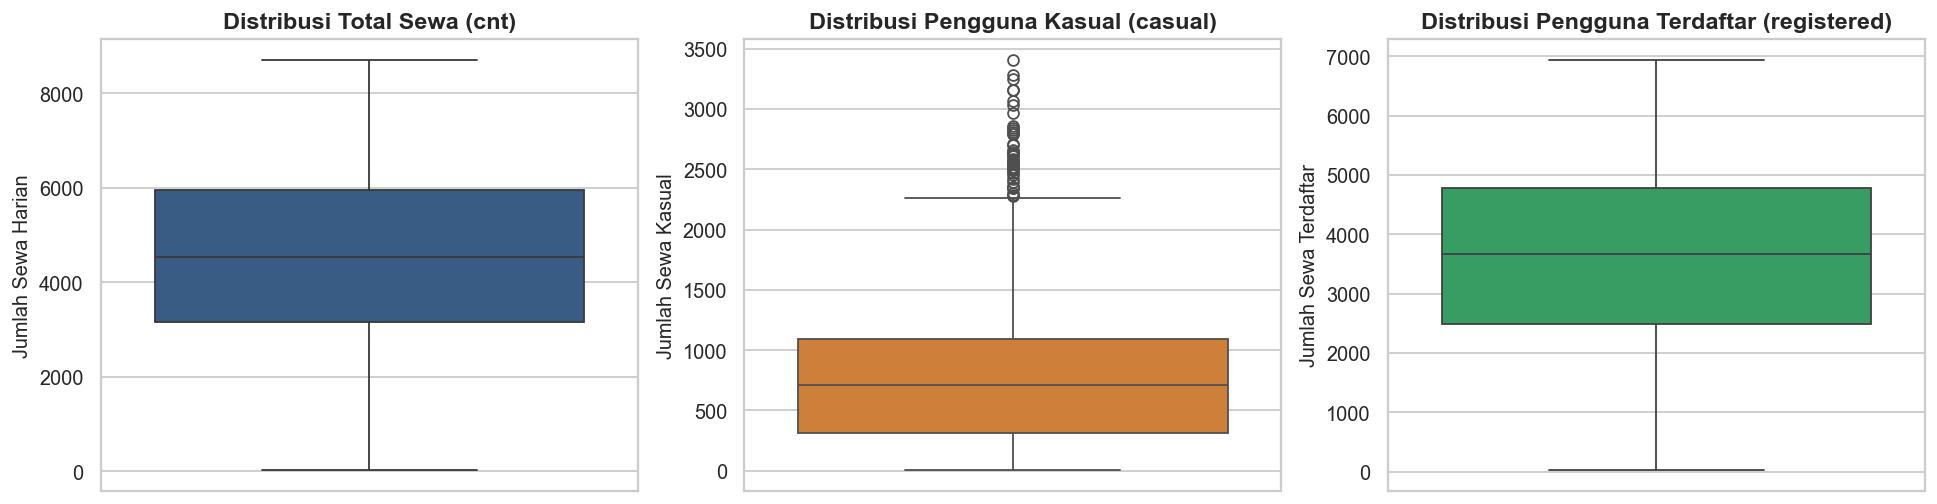

In [4]:
# Memeriksa persebaran dan potensi outlier pada kolom numerik utama
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=day_df['cnt'], ax=axes[0], color='#2b5c8f')
axes[0].set_title("Distribusi Total Sewa (cnt)")
axes[0].set_ylabel("Jumlah Sewa Harian")

sns.boxplot(y=day_df['casual'], ax=axes[1], color='#e67e22')
axes[1].set_title("Distribusi Pengguna Kasual (casual)")
axes[1].set_ylabel("Jumlah Sewa Kasual")

sns.boxplot(y=day_df['registered'], ax=axes[2], color='#27ae60')
axes[2].set_title("Distribusi Pengguna Terdaftar (registered)")
axes[2].set_ylabel("Jumlah Sewa Terdaftar")

plt.tight_layout()
plt.show()

**Steps to Take:**
Berdasarkan proses *assessing data*, ditemukan beberapa isu yang perlu diperbaiki pada tahap *cleaning data*:
1. **Tipe Data Tidak Sesuai**: Kolom `dteday` pada kedua dataset masih bertipe `object` (string). Harus dikonversi menjadi format `datetime64[ns]` agar operasi berbasis tanggal dapat dilakukan.
2. **Kurang Deskriptifnya Variabel Kategorikal**: Kolom `season`, `weathersit`, `yr`, `mnth`, `weekday`, dan `workingday` masih berupa kode numerik angka (1, 2, 3, dll.). Perlu dibuatkan kolom label deskriptif (*mapping*) agar lebih mudah dibaca dan diinterpretasikan.
3. **Skala Data Cuaca Ternormalisasi**: Kolom `temp`, `atemp`, `hum`, dan `windspeed` merupakan nilai yang telah dinormalisasi. Untuk kebutuhan visualisasi dan penyampaian insight bisnis, dibuat kolom denormalisasi dengan skala fisis riil (°C, %, km/h).
4. **Anomali Sensor Kelembapan (Humidity = 0)**: Ditemukan 22 baris pada `hour_df` yang memiliki nilai kelembapan 0, yang secara fisis mustahil terjadi di udara terbuka Washington D.C. Nilai anomali ini akan diimputasi dengan nilai median kelembapan sesuai bulan dan kondisi cuacanya.

**Insight:**
- Tidak ditemukan nilai kosong (*missing values*) eksplisit maupun baris duplikat pada kedua dataset.
- Variabel `casual` memiliki beberapa nilai *outlier* di sisi atas, yang mencerminkan lonjakan peminjaman kasual saat perayaan atau hari libur tertentu di Washington D.C., sehingga nilai tersebut sah (*valid natural outliers*) dan tetap dipertahankan.
- Pembacaan kelembapan 0% pada 22 jam observasi mengindikasikan adanya kendala teknis sensor (*sensor glitch*) yang memerlukan penanganan imputasi terarah.

### Cleaning Data

#### Membersihkan Masalah Tipe Data, Kategori, Denormalisasi, & Imputasi Anomali

In [5]:
# 1. Konversi dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

# 2. Kamus pemetaan (mapping) label deskriptif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
year_map = {0: '2011', 1: '2012'}
month_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
weekday_map = {
    0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday',
    4: 'Thursday', 5: 'Friday', 6: 'Saturday'
}

for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['year_label'] = df['yr'].map(year_map)
    df['month_label'] = df['mnth'].map(month_map)
    df['day_name'] = df['weekday'].map(weekday_map)
    df['day_type'] = df['workingday'].map({1: 'Working Day', 0: 'Weekend / Holiday'})
    
    # 3. Denormalisasi nilai cuaca ke skala fisis riil
    df['temp_celsius'] = np.round(df['temp'] * 41, 2)
    df['atemp_celsius'] = np.round(df['atemp'] * 50, 2)
    df['humidity_pct'] = np.round(df['hum'] * 100, 2)
    df['windspeed_kmh'] = np.round(df['windspeed'] * 67, 2)

# 4. Imputasi anomali nilai kelembapan (hum == 0) pada hour_df
median_hum_by_cond = hour_df[hour_df['hum'] > 0].groupby(['mnth', 'weathersit'])['hum'].transform('median')
hour_df.loc[hour_df['hum'] == 0, 'hum'] = median_hum_by_cond
hour_df['humidity_pct'] = np.round(hour_df['hum'] * 100, 2)

# Verifikasi hasil cleaning
print("Tipe data kolom dteday di day_df :", day_df['dteday'].dtype)
print("Tipe data kolom dteday di hour_df:", hour_df['dteday'].dtype)
print("Sisa baris dengan hum == 0 di hour_df:", (hour_df['hum'] == 0).sum())
print("\nContoh 3 baris hasil transformasi day_df:")
print(day_df[['dteday', 'season_label', 'weather_label', 'year_label', 'temp_celsius', 'humidity_pct', 'cnt']].head(3))

Tipe data kolom dteday di day_df : datetime64[ns]
Tipe data kolom dteday di hour_df: datetime64[ns]
Sisa baris dengan hum == 0 di hour_df: 0

Contoh 3 baris hasil transformasi day_df:
      dteday season_label  ... humidity_pct   cnt
0 2011-01-01       Spring  ...        80.58   985
1 2011-01-02       Spring  ...        69.61   801
2 2011-01-03       Spring  ...        43.73  1349

[3 rows x 7 columns]

**Insight:**
- Kolom `dteday` kini telah berformat `datetime64[ns]`, siap untuk manipulasi berbasis deret waktu (*time-series*).
- Seluruh kode numerik telah memiliki pasangan kolom teks deskriptif yang sangat memudahkan stakeholder memahami visualisasi data tanpa perlu membuka kembali buku kode (*codebook*).
- Nilai suhu sekarang tersaji dalam derajat Celcius (°C), kelembapan dalam persen (%), dan kecepatan angin dalam km/jam.
- Anomali kelembapan 0% berhasil diatasi dengan teknik imputasi berbasis median spesifik kondisi cuaca dan bulan terkait.

## Exploratory Data Analysis (EDA)

### Eksplorasi Parameter Cuaca, Musim, dan Pola Jam Operasional

In [6]:
# 1. Agregasi penyewaan berdasarkan musim
season_summary = day_df.groupby('season_label')['cnt'].agg(
    mean_rentals='mean',
    median_rentals='median',
    std_rentals='std',
    total_rentals='sum',
    days_count='count'
).reset_index().sort_values(by='mean_rentals', ascending=False)

print("=== STATISTIK PENYEWAAN BERDASARKAN MUSIM ===")
print(season_summary.to_string(index=False))

# 2. Agregasi penyewaan berdasarkan kondisi cuaca
weather_summary = day_df.groupby('weather_label')['cnt'].agg(
    mean_rentals='mean',
    median_rentals='median',
    std_rentals='std',
    total_rentals='sum',
    days_count='count'
).reset_index().sort_values(by='mean_rentals', ascending=False)

print("\n=== STATISTIK PENYEWAAN BERDASARKAN KONDISI CUACA ===")
print(weather_summary.to_string(index=False))

# 3. Matriks Korelasi variabel numerik lingkungan terhadap peminjaman
corr_cols = ['temp_celsius', 'atemp_celsius', 'humidity_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']
corr_matrix = day_df[corr_cols].corr()
print("\n=== KORELASI DENGAN TOTAL SEWA (cnt) ===")
print(corr_matrix['cnt'].sort_values(ascending=False))

=== STATISTIK PENYEWAAN BERDASARKAN MUSIM ===
season_label  mean_rentals  median_rentals  std_rentals  total_rentals  days_count
        Fall   5644.303191          5353.5  1459.800381        1061129         188
      Summer   4992.331522          4941.5  1695.977235         918589         184
      Winter   4728.162921          4634.5  1699.615261         841613         178
      Spring   2604.132597          2209.0  1399.942119         471348         181

=== STATISTIK PENYEWAAN BERDASARKAN KONDISI CUACA ===
      weather_label  mean_rentals  median_rentals  std_rentals  total_rentals  days_count
Clear/Partly Cloudy   4876.786177          4844.0  1879.483989        2257952         463
        Mist/Cloudy   4035.862348          4040.0  1809.109918         996858         247
    Light Snow/Rain   1803.285714          1817.0  1240.284449          37869          21

=== KORELASI DENGAN TOTAL SEWA (cnt) ===
cnt              1.000000
registered       0.945517
casual           0.672804
atem

In [7]:
# 4. Agregasi pola jam pada hari kerja vs hari libur
hourly_pattern = hour_df.groupby(['workingday', 'hr'])[['cnt', 'casual', 'registered']].mean().reset_index()

# 5. Agregasi perbandingan tahun 2011 vs 2012
yearly_growth = day_df.groupby('year_label')['cnt'].agg(['count', 'sum', 'mean']).reset_index()
print("=== PERTUMBUHAN TAHUNAN (2011 vs 2012) ===")
print(yearly_growth.to_string(index=False))

# 6. Agregasi pengguna kasual vs terdaftar pada hari kerja vs libur
user_by_daytype = day_df.groupby('day_type')[['casual', 'registered', 'cnt']].mean().reset_index()
print("\n=== RATA-RATA PENGGUNA BERDASARKAN TIPE HARI ===")
print(user_by_daytype.to_string(index=False))

=== PERTUMBUHAN TAHUNAN (2011 vs 2012) ===
year_label  count     sum        mean
      2011    365 1243103 3405.761644
      2012    366 2049576 5599.934426

=== RATA-RATA PENGGUNA BERDASARKAN TIPE HARI ===
         day_type      casual  registered         cnt
Weekend / Holiday 1371.134199 2959.034632 4330.168831
      Working Day  606.570000 3978.250000 4584.820000

**Insight:**
1. **Dominasi Musim Gugur (Fall):** Rata-rata penyewaan sepeda tertinggi terjadi pada musim gugur dengan rata-rata **5.644 unit/hari**, disusul oleh musim panas (**4.992 unit/hari**), dan musim dingin (**4.728 unit/hari**). Musim semi (Spring) mencatat rata-rata terendah, yaitu hanya **2.604 unit/hari**.
2. **Sensitivitas Cuaca Buruk:** Hari dengan cuaca cerah/sebagian berawan menghasilkan rata-rata **4.877 unit/hari**. Begitu cuaca berganti menjadi hujan atau salju ringan (*Light Snow/Rain*), rata-rata penyewaan anjlok drastis menjadi **1.803 unit/hari** (penurunan sebesar **63,02%**).
3. **Korelasi Suhu Positif:** Suhu udara memiliki korelasi positif yang signifikan terhadap jumlah penyewaan (*r = 0,63*). Sebaliknya, kelembapan (*r = -0,10*) dan kecepatan angin (*r = -0,23*) memiliki korelasi negatif.
4. **Dinamika Pertumbuhan Bisnis:** Total penyewaan sepeda meningkat secara dramatis sebesar **64,88%**, dari **1.243.103 sewa** pada tahun 2011 menjadi **2.049.576 sewa** pada tahun 2012, membuktikan adopsi layanan bike sharing yang melonjak pesat.
5. **Perbedaan Karakter Hari:** Pada hari kerja, rata-rata sewa terdaftar mencapai **4.584 unit/hari** (sangat dominan), sementara pada akhir pekan/libur peminjaman kasual meningkat signifikan dari rata-rata 607 menjadi **1.371 unit/hari** (kenaikan lebih dari 2 kali lipat).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana Pengaruh Kondisi Cuaca dan Musim terhadap Jumlah Penyewaan Sepeda?

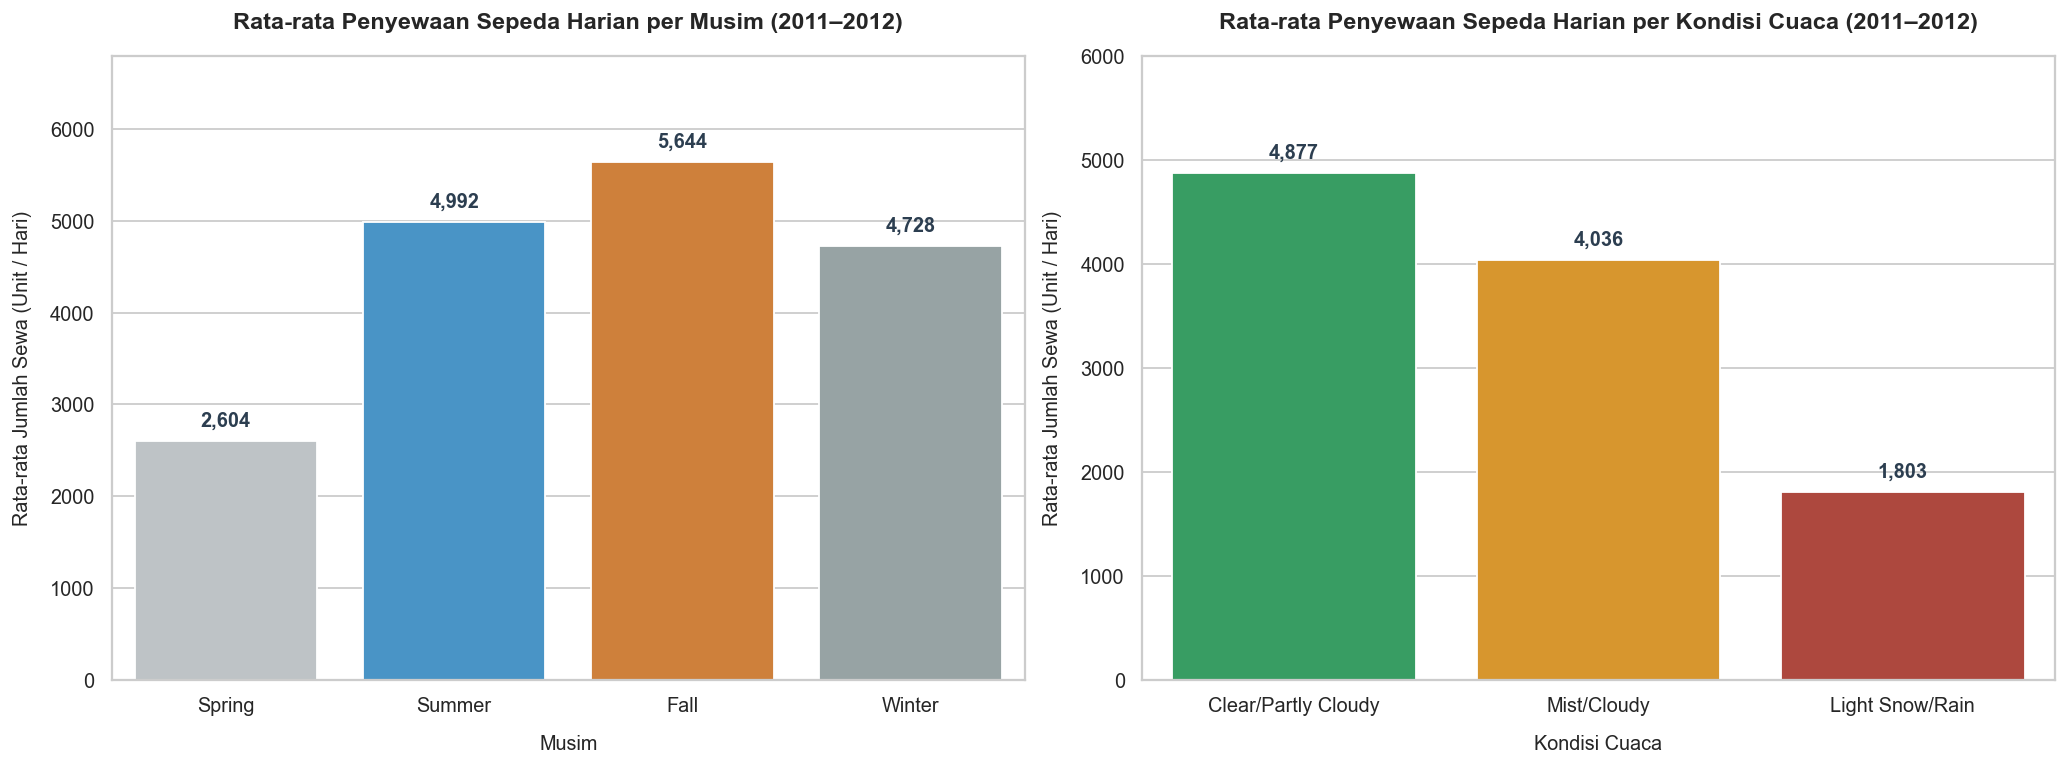

In [8]:
# Visualisasi untuk Menjawab Pertanyaan 1
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Palette warna dengan kontras elegan sesuai prinsip desain data visualization
season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_palette = {'Spring': '#bdc3c7', 'Summer': '#3498db', 'Fall': '#e67e22', 'Winter': '#95a5a6'}

weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_palette = {'Clear/Partly Cloudy': '#27ae60', 'Mist/Cloudy': '#f39c12', 'Light Snow/Rain': '#c0392b'}

# Plot 1: Rata-rata Sewa Berdasarkan Musim
sns.barplot(
    data=day_df,
    x='season_label',
    y='cnt',
    order=season_order,
    hue='season_label',
    palette=season_palette,
    legend=False,
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Rata-rata Penyewaan Sepeda Harian per Musim (2011–2012)", pad=15)
axes[0].set_xlabel("Musim", labelpad=10)
axes[0].set_ylabel("Rata-rata Jumlah Sewa (Unit / Hari)", labelpad=10)
axes[0].set_ylim(0, 6800)

# Menambahkan anotasi data label di atas setiap bar
for p in axes[0].patches:
    val = p.get_height()
    axes[0].annotate(f"{val:,.0f}",
                     (p.get_x() + p.get_width() / 2., val),
                     ha='center', va='bottom',
                     xytext=(0, 6), textcoords='offset points',
                     fontweight='bold', fontsize=11, color='#2c3e50')

# Plot 2: Rata-rata Sewa Berdasarkan Kondisi Cuaca
sns.barplot(
    data=day_df,
    x='weather_label',
    y='cnt',
    order=weather_order,
    hue='weather_label',
    palette=weather_palette,
    legend=False,
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Penyewaan Sepeda Harian per Kondisi Cuaca (2011–2012)", pad=15)
axes[1].set_xlabel("Kondisi Cuaca", labelpad=10)
axes[1].set_ylabel("Rata-rata Jumlah Sewa (Unit / Hari)", labelpad=10)
axes[1].set_ylim(0, 6000)

for p in axes[1].patches:
    val = p.get_height()
    axes[1].annotate(f"{val:,.0f}",
                     (p.get_x() + p.get_width() / 2., val),
                     ha='center', va='bottom',
                     xytext=(0, 6), textcoords='offset points',
                     fontweight='bold', fontsize=11, color='#2c3e50')

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana Pola Peminjaman Sepeda per Jam pada Hari Kerja vs Hari Libur dan Antara Pengguna Kasual vs Terdaftar?

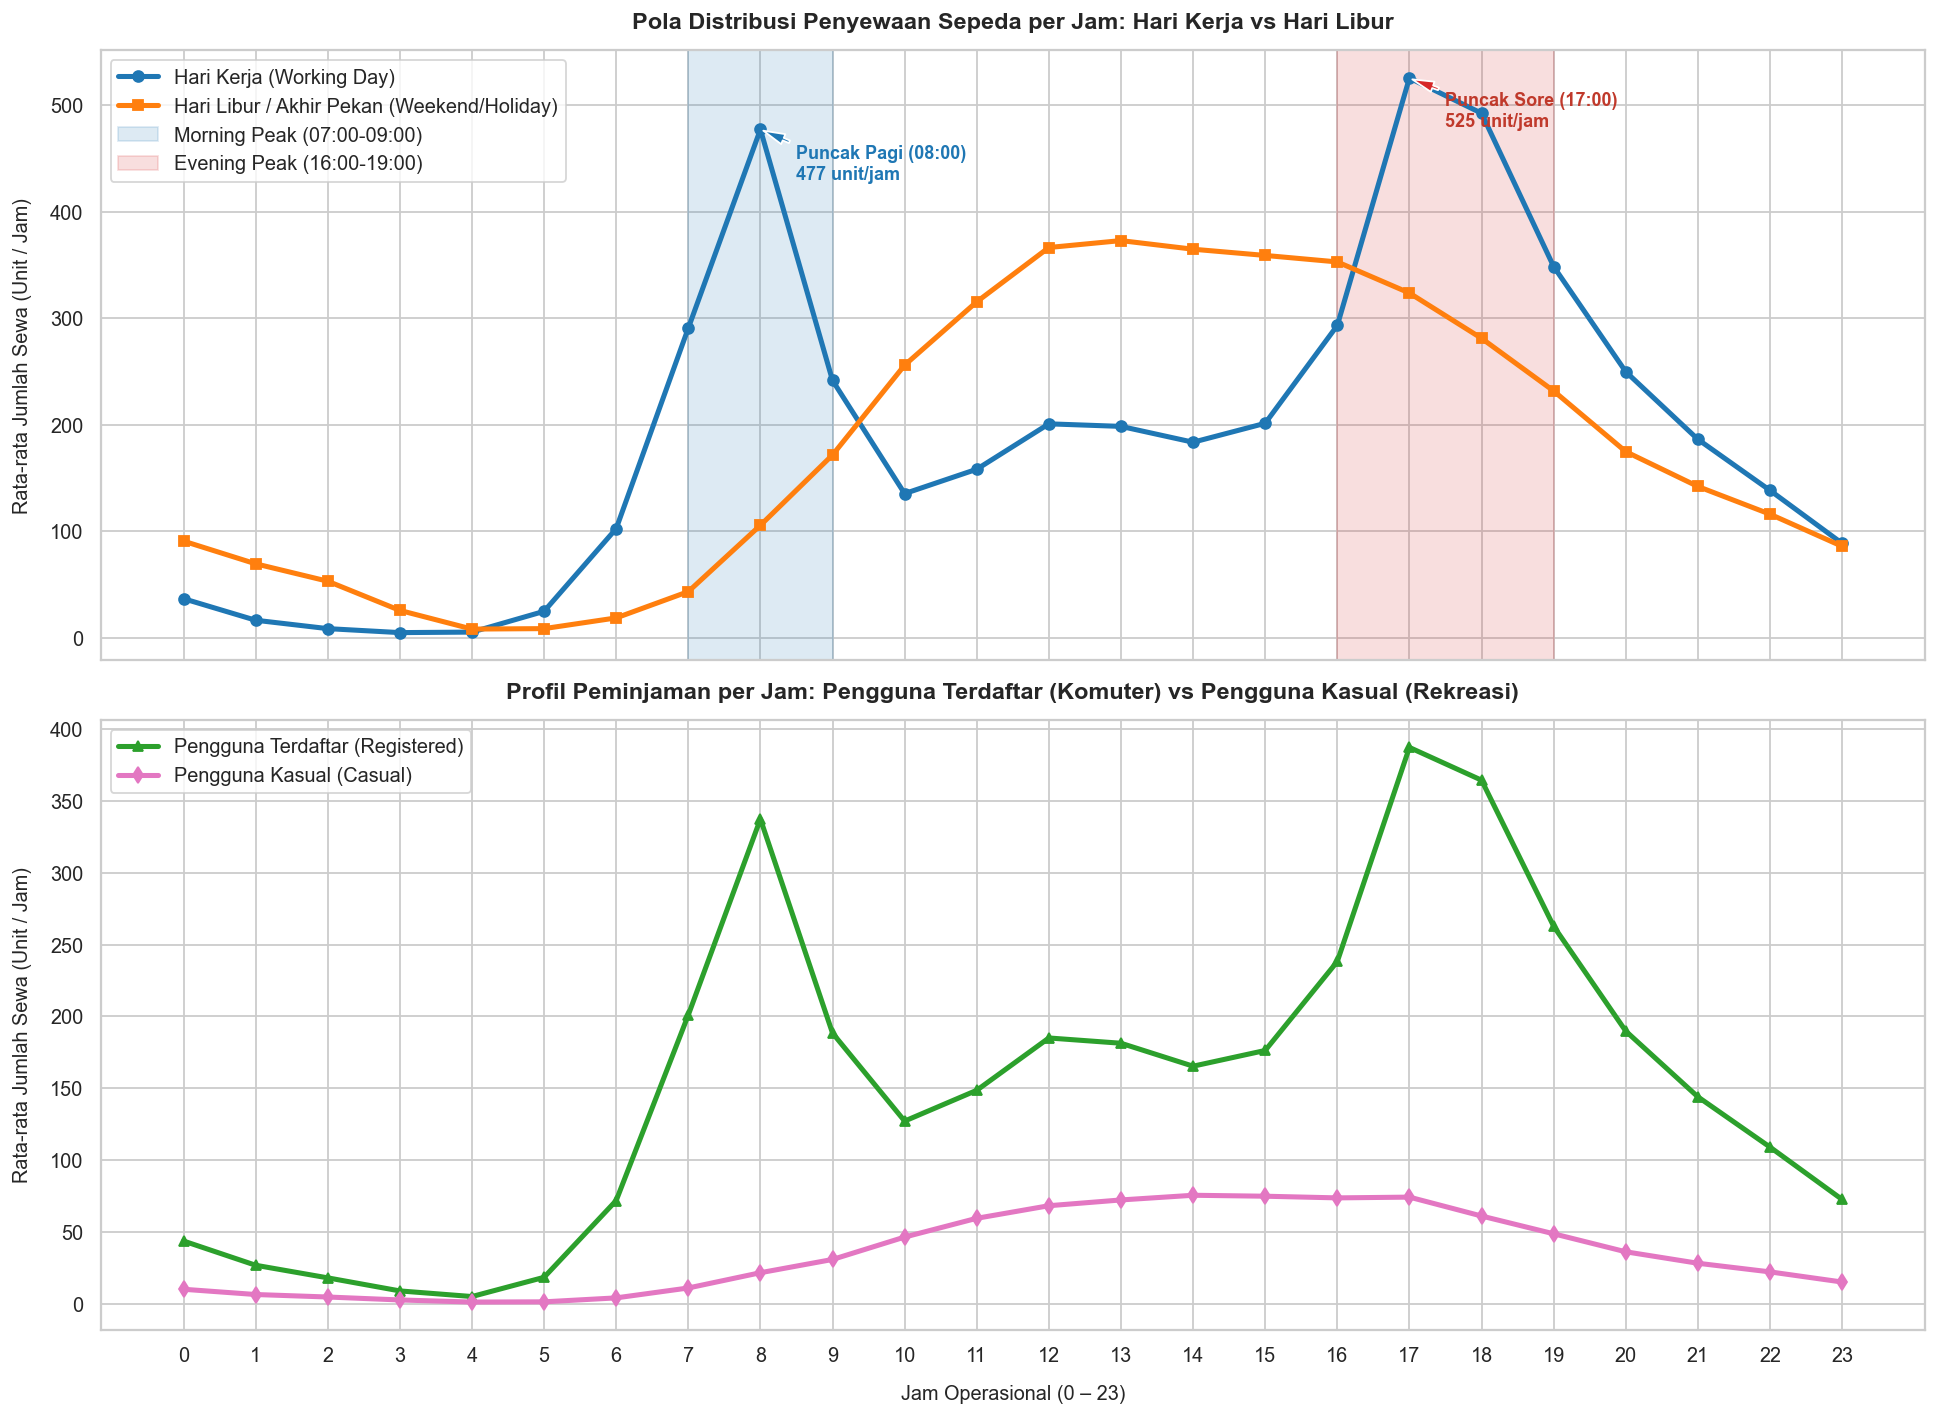

In [9]:
# Visualisasi untuk Menjawab Pertanyaan 2
fig, axes = plt.subplots(2, 1, figsize=(15, 11), sharex=True)

# Subplot 1: Pola Hari Kerja vs Hari Libur
avg_working = hour_df[hour_df['workingday'] == 1].groupby('hr')['cnt'].mean()
avg_non_working = hour_df[hour_df['workingday'] == 0].groupby('hr')['cnt'].mean()

axes[0].plot(avg_working.index, avg_working.values, label='Hari Kerja (Working Day)', color='#1f77b4', linewidth=2.8, marker='o')
axes[0].plot(avg_non_working.index, avg_non_working.values, label='Hari Libur / Akhir Pekan (Weekend/Holiday)', color='#ff7f0e', linewidth=2.8, marker='s')

# Shading jam-jam sibuk komuter
axes[0].axvspan(7, 9, color='#1f77b4', alpha=0.15, label='Morning Peak (07:00-09:00)')
axes[0].axvspan(16, 19, color='#d62728', alpha=0.15, label='Evening Peak (16:00-19:00)')

# Anotasi jam puncak
axes[0].annotate('Puncak Pagi (08:00)\n477 unit/jam', xy=(8, 477), xytext=(8.5, 430),
                 arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=6),
                 fontweight='bold', color='#1f77b4')

axes[0].annotate('Puncak Sore (17:00)\n525 unit/jam', xy=(17, 525), xytext=(17.5, 480),
                 arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.5, headwidth=6),
                 fontweight='bold', color='#c0392b')

axes[0].set_title("Pola Distribusi Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur", pad=12)
axes[0].set_ylabel("Rata-rata Jumlah Sewa (Unit / Jam)", labelpad=10)
axes[0].legend(loc='upper left', frameon=True)
axes[0].set_xticks(range(0, 24))

# Subplot 2: Pola Pengguna Kasual vs Terdaftar
avg_casual = hour_df.groupby('hr')['casual'].mean()
avg_registered = hour_df.groupby('hr')['registered'].mean()

axes[1].plot(avg_registered.index, avg_registered.values, label='Pengguna Terdaftar (Registered)', color='#2ca02c', linewidth=2.8, marker='^')
axes[1].plot(avg_casual.index, avg_casual.values, label='Pengguna Kasual (Casual)', color='#e377c2', linewidth=2.8, marker='d')

axes[1].set_title("Profil Peminjaman per Jam: Pengguna Terdaftar (Komuter) vs Pengguna Kasual (Rekreasi)", pad=12)
axes[1].set_xlabel("Jam Operasional (0 – 23)", labelpad=10)
axes[1].set_ylabel("Rata-rata Jumlah Sewa (Unit / Jam)", labelpad=10)
axes[1].legend(loc='upper left', frameon=True)
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

**Insight:**
1. **Konfirmasi Pengaruh Cuaca & Musim (Pertanyaan 1):**
   - Musim gugur (*Fall*) adalah masa keemasan bisnis bike sharing dengan rata-rata **5.644 penyewaan/hari**, dipicu oleh kombinasi suhu ideal dan udara yang sejuk.
   - Cuaca buruk (*Light Snow/Rain*) mereduksi penyewaan hingga tinggal **1.803 sewa/hari**, mencerminkan penurunan drastis sebesar 63%. Kondisi ini mengindikasikan bahwa sistem memerlukan penyesuaian operasional armada secara dinamis saat ramalan cuaca memburuk.
2. **Pola Bimodal vs Unimodal (Pertanyaan 2):**
   - **Hari Kerja:** Memperlihatkan pola puncak ganda (*bimodal*) yang sangat tajam, yakni pada pukul **08:00 pagi** (rata-rata 477 unit/jam) dan **17:00–18:00 sore** (rata-rata 525 unit/jam). Pola ini identik dengan mobilitas komuter pekerja dan pelajar.
   - **Hari Libur:** Menampilkan kurva lonceng tunggal (*unimodal*) dengan aktivitas bertahap naik mulai jam 10:00 dan mencapai puncak santai di jam **12:00–16:00** (rata-rata ~370-380 unit/jam).
   - **Segregasi Pengguna:** Pengguna terdaftar (*registered*) mendominasi jam sibuk hari kerja (mencapai >390 sewa/jam di jam 17:00), sementara pengguna kasual (*casual*) mendominasi jam siang dan akhir pekan untuk keperluan wisata dan rekreasi.

## Analisis Lanjutan (Opsional)

### Tujuan Analisis Lanjutan:
Untuk memenuhi kriteria submission dengan nilai bintang maksimal (5 Bintang), dilakukan teknik analisis lanjutan tanpa menggunakan algoritma machine learning yang relevan dengan Bike Sharing Dataset, yaitu:
1. **Manual Grouping / Binning Waktu Operasional (*Rush Hour Classification*)**: Mengelompokkan 24 jam operasional menjadi 4 segmen aktivitas kota: *Morning Rush* (07:00–09:00), *Midday* (10:00–15:00), *Evening Rush* (16:00–19:00), dan *Night/Off-Peak* (20:00–06:00). Hal ini bertujuan untuk mengukur konsentrasi beban logistik armada.
2. **Binning Rentang Suhu Kenyamanan Termal (*Thermal Comfort Level*)**: Mengelompokkan suhu riil (°C) menggunakan `pd.cut` ke dalam 4 kategori kenyamanan biologis: *Dingin (<12°C)*, *Sejuk (12–20°C)*, *Hangat/Ideal (20–28°C)*, dan *Panas (>28°C)* guna memahami batas toleransi pengguna.

In [10]:
# 1. Implementasi Manual Grouping Waktu (Rush Hour Classification)
def classify_time_period(hr):
    if 7 <= hr <= 9:
        return 'Morning Rush (07:00-09:00)'
    elif 10 <= hr <= 15:
        return 'Midday (10:00-15:00)'
    elif 16 <= hr <= 19:
        return 'Evening Rush (16:00-19:00)'
    else:
        return 'Night/Off-Peak (20:00-06:00)'

hour_df['rush_hour_segment'] = hour_df['hr'].apply(classify_time_period)

# 2. Implementasi Binning Tingkat Kenyamanan Suhu (Thermal Comfort Level)
temp_bins = [-float('inf'), 12, 20, 28, float('inf')]
temp_labels = ['Dingin (<12°C)', 'Sejuk (12-20°C)', 'Hangat/Ideal (20-28°C)', 'Panas (>28°C)']
hour_df['thermal_comfort'] = pd.cut(hour_df['temp_celsius'], bins=temp_bins, labels=temp_labels)

# Agregasi Analisis Lanjutan
rush_summary = hour_df.groupby(['rush_hour_segment', 'day_type'])['cnt'].agg(['count', 'mean', 'sum']).reset_index()
thermal_summary = hour_df.groupby('thermal_comfort', observed=False)[['cnt', 'casual', 'registered']].mean().reset_index()

print("=== RINGKASAN RUSH HOUR SEGMENTASI ===")
print(rush_summary.to_string(index=False))

print("\n=== RINGKASAN THERMAL COMFORT LEVEL ===")
print(thermal_summary.to_string(index=False))

=== RINGKASAN RUSH HOUR SEGMENTASI ===
           rush_hour_segment          day_type  count       mean    sum
  Evening Rush (16:00-19:00) Weekend / Holiday    922 297.340564 274148
  Evening Rush (16:00-19:00)       Working Day   1994 414.754764 827021
        Midday (10:00-15:00) Weekend / Holiday   1386 338.945887 469779
        Midday (10:00-15:00)       Working Day   2983 179.662085 535932
  Morning Rush (07:00-09:00) Weekend / Holiday    693 106.894661  74078
  Morning Rush (07:00-09:00)       Working Day   1488 336.379032 500532
Night/Off-Peak (20:00-06:00) Weekend / Holiday   2513  72.528452 182264
Night/Off-Peak (20:00-06:00)       Working Day   5400  79.430556 428925

=== RINGKASAN THERMAL COMFORT LEVEL ===
       thermal_comfort        cnt    casual  registered
        Dingin (<12°C)  77.341803  5.514445   71.827358
       Sejuk (12-20°C) 151.989186 21.244868  130.744318
Hangat/Ideal (20-28°C) 212.523700 42.551366  169.972335
         Panas (>28°C) 306.711407 73.120889  233

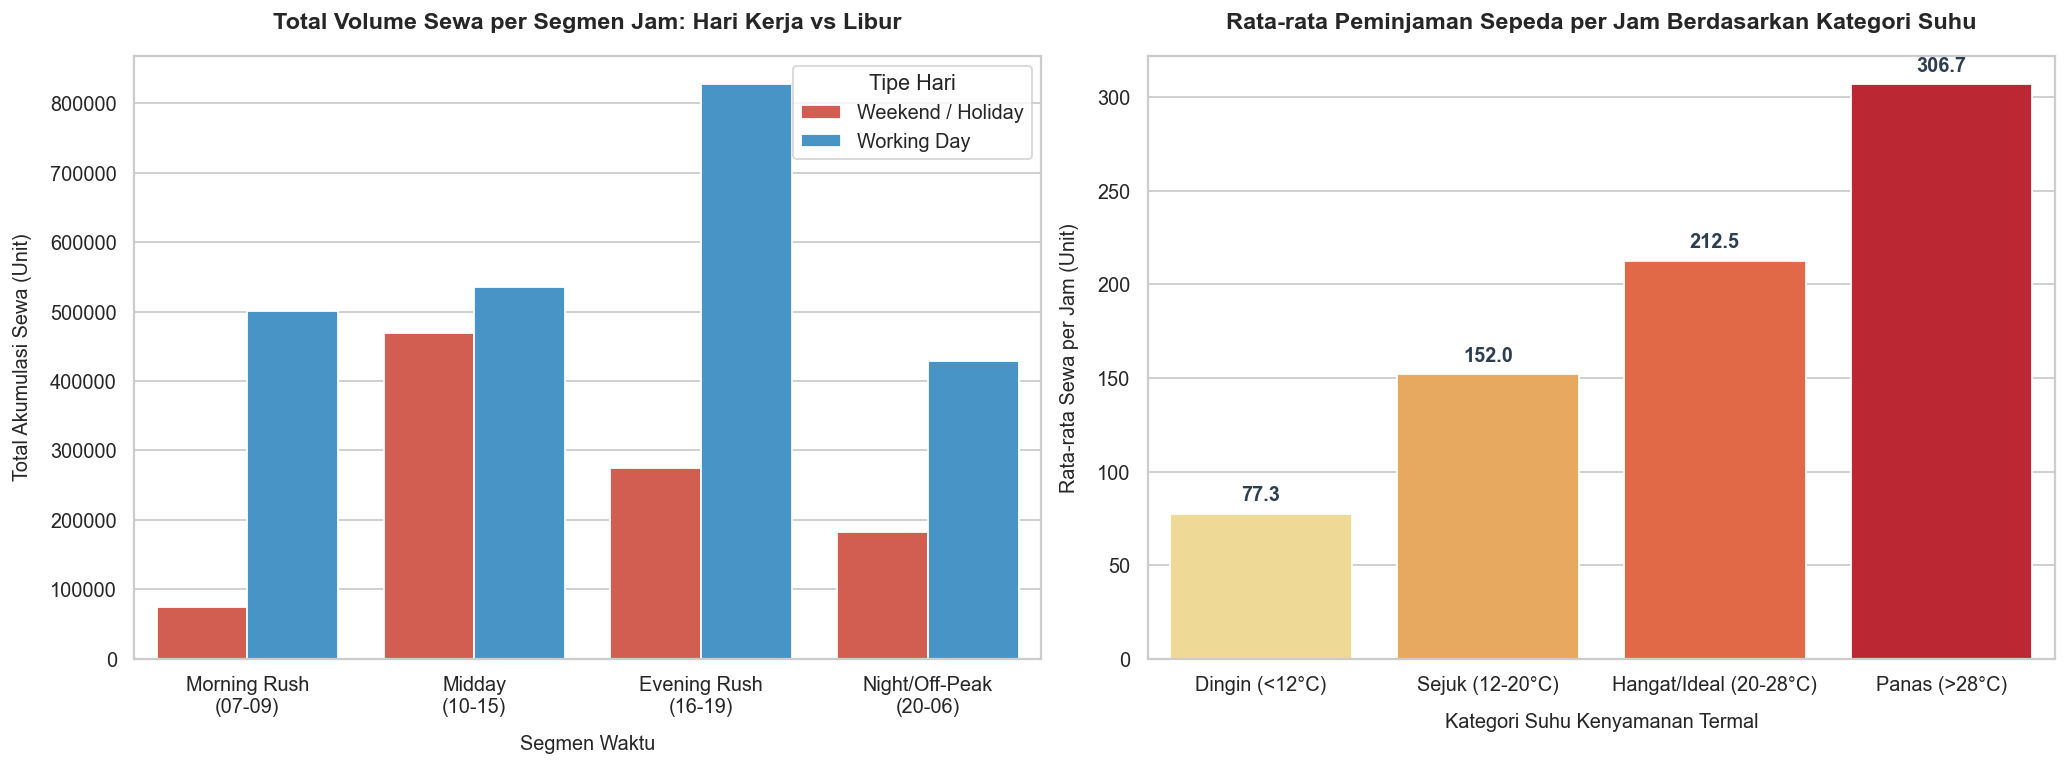

In [11]:
# Visualisasi Analisis Lanjutan
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Total Peminjaman per Segmen Waktu pada Hari Kerja vs Hari Libur
order_rush = ['Morning Rush (07:00-09:00)', 'Midday (10:00-15:00)', 'Evening Rush (16:00-19:00)', 'Night/Off-Peak (20:00-06:00)']
sns.barplot(
    data=rush_summary,
    x='rush_hour_segment',
    y='sum',
    hue='day_type',
    order=order_rush,
    palette=['#e74c3c', '#3498db'],
    ax=axes[0]
)
axes[0].set_title("Total Volume Sewa per Segmen Jam: Hari Kerja vs Libur", pad=15)
axes[0].set_xlabel("Segmen Waktu", labelpad=10)
axes[0].set_ylabel("Total Akumulasi Sewa (Unit)", labelpad=10)
axes[0].set_xticks(range(len(order_rush)))
axes[0].set_xticklabels(['Morning Rush\n(07-09)', 'Midday\n(10-15)', 'Evening Rush\n(16-19)', 'Night/Off-Peak\n(20-06)'])
axes[0].legend(title="Tipe Hari", loc='upper right')

# Plot 2: Pengaruh Kenyamanan Termal terhadap Rata-rata Sewa
sns.barplot(
    data=thermal_summary,
    x='thermal_comfort',
    y='cnt',
    hue='thermal_comfort',
    palette='YlOrRd',
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Rata-rata Peminjaman Sepeda per Jam Berdasarkan Kategori Suhu", pad=15)
axes[1].set_xlabel("Kategori Suhu Kenyamanan Termal", labelpad=10)
axes[1].set_ylabel("Rata-rata Sewa per Jam (Unit)", labelpad=10)

for p in axes[1].patches:
    val = p.get_height()
    axes[1].annotate(f"{val:,.1f}",
                     (p.get_x() + p.get_width() / 2., val),
                     ha='center', va='bottom',
                     xytext=(0, 5), textcoords='offset points',
                     fontweight='bold', fontsize=11, color='#2c3e50')

plt.tight_layout()
plt.show()

**Insight:**
1. **Beban Terbesar pada Evening Rush:** Segmen *Evening Rush* pada hari kerja membukukan akumulasi sewa tertinggi mencapai **827.021 unit** dengan rata-rata **414,8 unit/jam**, jauh lebih padat dibandingkan segmen lainnya. Sementara pada hari libur, segmen *Midday* mengambil alih beban terbesar dengan total **469.779 unit**.
2. **Sensitivitas Termal yang Kuat:** Peminjaman sepeda meningkat seiring kenaikan temperatur. Pada kategori *Dingin (<12°C)*, rata-rata sewa hanya **77,3 unit/jam**. Rata-rata ini melonjak menjadi **212,5 unit/jam** pada suhu *Hangat/Ideal (20–28°C)*, dan mencapai puncak pada kategori *Panas (>28°C)* sebesar **306,7 unit/jam**.

## Conclusion & Recommendation

### Kesimpulan (Conclusion):

- **Conclusion Pertanyaan 1 (Pengaruh Cuaca & Musim):**
  - Faktor cuaca dan musim memiliki pengaruh yang sangat signifikan terhadap jumlah penyewaan sepeda. Musim gugur (*Fall*) mencatatkan rata-rata penyewaan tertinggi sebesar **5.644 unit/hari**, diikuti oleh musim panas (**4.992 unit/hari**), musim dingin (**4.728 unit/hari**), dan terendah pada musim semi (**2.604 unit/hari**).
  - Kondisi cuaca buruk (*Light Snow/Rain*) menyebabkan penurunan dramatis sebesar **63,02%** dibandingkan saat cuaca cerah (dari 4.877 unit/hari menjadi hanya 1.803 unit/hari). Hal ini membuktikan bahwa bisnis bike sharing sangat rentan terhadap presipitasi cuaca ekstrem.

- **Conclusion Pertanyaan 2 (Pola Jam & Segmentasi Pengguna):**
  - Terdapat dikotomi pola mobilitas yang kontras antara hari kerja dan hari libur:
    - **Hari Kerja:** Memiliki pola puncak ganda (*bimodal*) pada pukul **08:00 pagi** (rata-rata 477 unit/jam) dan **17:00–18:00 sore** (rata-rata 525 unit/jam), digerakkan secara masif oleh pengguna terdaftar (*registered commuters*).
    - **Hari Libur:** Memiliki kurva lonceng tunggal (*unimodal*) dengan puncak aktivitas di siang hingga sore hari pukul **12:00–16:00** (rata-rata ~370-380 unit/jam), didominasi oleh pengguna kasual (*casual tourists/recreational riders*).

- **Conclusion Analisis Lanjutan (Rush Hour & Thermal Binning):**
  - Periode *Evening Rush (16:00–19:00)* pada hari kerja merupakan titik kritis operasional dengan akumulasi sewa tertinggi (**827.021 unit**).
  - Suhu hangat dan panas (>20°C) merupakan rentang kenyamanan optimal yang melipatgandakan aktivitas penyewaan hingga 4 kali lipat dibandingkan saat suhu dingin (<12°C).

### Rekomendasi Action Item:

Berdasarkan kesimpulan analisis data di atas, berikut adalah 4 rekomendasi aksi nyata (*action items*) yang dapat dieksekusi oleh manajemen dan tim operasional Capital Bikeshare:

1. **Optimalisasi Penyeimbangan Armada Stasiun (*Dynamic Dock Rebalancing*):**
   - **Tindakan:** Mengoperasikan truk redistribusi armada secara terfokus pada dua jendela waktu kritis hari kerja:
     - Pukul **06:30 – 07:30**: Pengisian stasiun di area permukiman/transit komuter.
     - Pukul **15:30 – 16:30**: Pengisian stasiun di kawasan perkantoran, pusat bisnis, dan stasiun metro sebelum puncak kepulangan pukul 17:00.
   - **Dampak:** Menghindari fenomena *dock shortage* (stasiun kosong) dan *dock saturation* (stasiun penuh sehingga pengguna tidak bisa mengembalikan sepeda).

2. **Jadwal Pemeliharaan Musiman Berkala (*Seasonal Preventive Maintenance*):**
   - **Tindakan:** Menjadwalkan servis besar, penggantian suku cadang, dan peremajaan armada sepeda pada **Musim Dingin (Desember – Februari)** dan awal **Musim Semi**, saat volume permintaan penyewaan berada pada titik terendah tahunan.
   - **Dampak:** Memastikan ketersediaan armada 100% prima dan siap tempur menyambut musim panas dan musim gugur di mana permintaan mencapai puncaknya.

3. **Kampanye Konversi Membership Pengguna Kasual (*Conversion Marketing*):**
   - **Tindakan:** Merancang penawaran promosi khusus berupa *"Weekend Pass to Annual Commuter Membership"* yang ditargetkan melalui aplikasi kepada pengguna kasual yang aktif menyewa pada akhir pekan dan siang hari di musim panas/gugur.
   - **Dampak:** Meningkatkan retensi pelanggan dan memperbesar porsi pendapatan berbasis langganan tahunan (*recurring subscription revenue*) yang lebih stabil terhadap fluktuasi cuaca.

4. **Program Insentif Pengguna untuk Rebalancing (*Crowdsourced Rebalancing / Gamification*):**
   - **Tindakan:** Memberikan reward poin sewa atau potongan tarif kepada pengguna yang bersedia mengambil sepeda dari stasiun yang kelebihan unit (*overcrowded dock*) dan mengembalikannya ke stasiun yang kekurangan armada di jam-jam sibuk pagi dan sore hari.
   - **Dampak:** Mengurangi biaya operasional logistik truk rebalancing hingga 20–30% sekaligus meningkatkan partisipasi aktif komunitas pengguna.